# Comparing all models

Four models, one test set (original data, 12.3% churn). Every model uses the same 80/20 split, the same blank-filling and the same data **lottery** (random undersampling of stayers in the training set).

| # | Model | Decision rule |
|---|---|---|
| 1 | Random forest + lottery | fixed threshold 0.45 |
| 2 | Logistic regression + lottery | threshold from a 60% recall target |
| 3 | Neural network, dense (all 3,360 weights) + lottery | threshold from a 60% recall target |
| 4 | Neural network, **winning ticket** (about 6% of weights, from the Lottery Ticket procedure) + lottery | threshold from a 60% recall target |

Models 3 and 4 come from the Lottery Ticket experiment in notebook 03. The earlier notebooks judged the network only by AUC; here it gets the same confusion-matrix and false-alarm comparison as the other models.

> Two different "lotteries" appear in this project: the **data lottery** (undersampling, used by every model) and the **Lottery Ticket Hypothesis** (pruning a neural network, used only for model 4).

In [1]:
import warnings, math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline as SklearnPipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, balanced_accuracy_score, roc_auc_score, average_precision_score, roc_curve
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline

## 1. Data, split and preparation

In [2]:
NAME = "employee_churn_ecommerce_retail_5000_10cols.csv"
candidates = [Path(NAME), Path("data") / NAME, Path("..") / "data" / NAME, Path("..") / NAME]
DATA_PATH = next((p for p in candidates if p.exists()), None)
assert DATA_PATH is not None, f"Could not find {NAME}. Put it next to this notebook or in a data/ folder."

df = pd.read_csv(DATA_PATH)
y = df["termination_date"].notna().astype(int)                   # blank termination date = still employed
X = df.drop(columns=["termination_date", "employee_id"])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)
P, N = int(y_test.sum()), int((y_test == 0).sum())
yv = y_test.values
print(f"Churn rate {y.mean():.1%} | test set: {len(y_test)} employees = {P} leavers + {N} stayers")

num = X_train.select_dtypes(include="number").columns.tolist()
cat = X_train.select_dtypes(exclude="number").columns.tolist()
def make_pre():
    return ColumnTransformer([
        ("numeric", SklearnPipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), num),
        ("categorical", SklearnPipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                                         ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat)])
def lottery():
    return RandomUnderSampler(sampling_strategy=0.45, random_state=42)

def threshold_from_recall(scores, labels, target):
    """cut-off so that about `target` of the real leavers score above it (computed from TRAINING scores only)"""
    pos = np.sort(scores[labels == 1])
    return float(pos[int(np.floor((1 - target) * len(pos)))])

results = {}      # name -> (test probabilities, threshold)

Churn rate 12.3% | test set: 1000 employees = 123 leavers + 877 stayers


## 2. Models 1 and 2 - random forest and logistic regression

In [3]:
# Model 1: random forest, fixed threshold
rf = Pipeline([("pre", make_pre()), ("lottery", lottery()),
               ("clf", RandomForestClassifier(n_estimators=200, random_state=42))]).fit(X_train, y_train)
results["1 Random forest"] = (rf.predict_proba(X_test)[:, 1], 0.45)

# Model 2: logistic regression, threshold from a 60% recall target (cross-validated on training data)
lr = Pipeline([("pre", make_pre()), ("lottery", lottery()), ("clf", LogisticRegression(max_iter=1000))])
oof = cross_val_predict(lr, X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=42), method="predict_proba")[:, 1]
thr_lr = threshold_from_recall(oof, y_train.values, 0.60)
lr.fit(X_train, y_train)
results["2 Logistic regression"] = (lr.predict_proba(X_test)[:, 1], thr_lr)
print("Models 1 and 2 trained.")

Models 1 and 2 trained.


## 3. Models 3 and 4 - the neural network and its winning ticket

A small network (inputs -> 64 -> 32 -> 1) written in NumPy. **Lottery Ticket procedure:** train, prune the smallest 20% of weights in each layer, rewind the survivors to their original starting values, repeat 13 times. That leaves about 6% of the weights (the *winning ticket*). Model 3 is the same network with nothing pruned. Details and a 10-seed study are in notebook 03.

In [4]:
prep = make_pre().fit(X_train)
Z_full = prep.transform(X_train).astype(float)
Z_test = prep.transform(X_test).astype(float)
Z_bal, y_bal = lottery().fit_resample(Z_full, y_train.values)        # data lottery, applied once to the training set

D = Z_full.shape[1]; sizes = (D, 64, 32, 1)
EPOCHS, LR, BATCH, WD, PRUNE_RATE = 25, 0.003, 128, 0.1, 0.20       # settings tuned on a validation split of the training data

def init_weights(rng):
    return ([rng.normal(0, np.sqrt(2.0 / sizes[i]), (sizes[i], sizes[i + 1])) for i in range(3)],
            [np.zeros(sizes[i + 1]) for i in range(3)])
def forward(W, b, Xb):
    acts = [Xb]
    for i in range(3):
        z = acts[-1] @ W[i] + b[i]; acts.append(z if i == 2 else np.maximum(z, 0))
    return acts
def predict(W, b, Xb):
    return 1 / (1 + np.exp(-forward(W, b, Xb)[-1][:, 0]))
def train(W, b, masks, rng, Zt, yt):
    W = [w * m for w, m in zip(W, masks)]; b = [x.copy() for x in b]
    mW = [np.zeros_like(w) for w in W]; vW = [np.zeros_like(w) for w in W]
    mb = [np.zeros_like(x) for x in b]; vb = [np.zeros_like(x) for x in b]; t = 0; n = len(yt)
    for _ in range(EPOCHS):
        idx = rng.permutation(n)
        for s in range(0, n, BATCH):
            ib = idx[s:s + BATCH]; a = forward(W, b, Zt[ib])
            p = 1 / (1 + np.exp(-a[-1][:, 0])); d = ((p - yt[ib]) / len(ib))[:, None]; t += 1
            for i in range(2, -1, -1):
                gW = a[i].T @ d + WD * W[i]; gb = d.sum(0)
                if i > 0: d = (d @ W[i].T) * (a[i] > 0)
                gW = gW * masks[i]
                for (m_, v_, g_, par) in ((mW, vW, gW, W), (mb, vb, gb, b)):
                    m_[i] = 0.9 * m_[i] + 0.1 * g_; v_[i] = 0.999 * v_[i] + 0.001 * g_ ** 2
                    par[i] = par[i] - LR * (m_[i] / (1 - 0.9 ** t)) / (np.sqrt(v_[i] / (1 - 0.999 ** t)) + 1e-8)
                W[i] = W[i] * masks[i]
    return W, b
def prune(W, masks):
    new = []
    for i, (w, m) in enumerate(zip(W, masks)):
        rate = PRUNE_RATE if i < 2 else PRUNE_RATE / 2
        alive = np.abs(w[m == 1]); k = int(round(rate * alive.size))
        if k > 0 and alive.size > 1:
            cut = np.partition(alive, k - 1)[k - 1]; m = m * (np.abs(w) > cut)
        new.append(m)
    return new

# --- find the winning ticket: train, prune, rewind to the ORIGINAL weights, repeat ---
W0, b0 = init_weights(np.random.default_rng(100))                    # the original starting weights
dense_mask = [np.ones_like(w) for w in W0]; total = sum(w.size for w in W0)
ticket_mask = dense_mask
for rnd in range(13):
    Wt, bt = train(W0, b0, ticket_mask, np.random.default_rng(1000 + rnd), Z_bal, y_bal)
    ticket_mask = prune(Wt, ticket_mask)
kept = int(sum(m.sum() for m in ticket_mask))
print(f"Winning ticket keeps {kept} of {total} weights ({100 * kept / total:.1f}%)")

def nn_threshold(mask, target=0.60):
    """5-fold cross-validated training scores -> cut-off for the recall target (training data only)"""
    oof = np.zeros(len(y_train))
    for tr, te in StratifiedKFold(5, shuffle=True, random_state=42).split(Z_full, y_train):
        Zs, ys = lottery().fit_resample(Z_full[tr], y_train.values[tr])
        W, b = train(W0, b0, mask, np.random.default_rng(7), Zs, ys); oof[te] = predict(W, b, Z_full[te])
    return threshold_from_recall(oof, y_train.values, target)
def nn_scores(mask, seed):
    W, b = train(W0, b0, mask, np.random.default_rng(seed), Z_bal, y_bal); return predict(W, b, Z_test)

results["3 Neural net (dense)"] = (nn_scores(dense_mask, 2000), nn_threshold(dense_mask))
results["4 Neural net (winning ticket)"] = (nn_scores(ticket_mask, 2001), nn_threshold(ticket_mask))
print("Models 3 and 4 trained.")

Winning ticket keeps 190 of 3360 weights (5.7%)


Models 3 and 4 trained.


## 4. Results at each model's own setting
Rows 2-4 aim for 60% recall; row 1 uses its fixed 0.45, so the models catch different numbers of leavers. Compare false alarms like for like in section 7.

In [5]:
rows = []
for name, (p, thr) in results.items():
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(yv, pred).ravel()
    rows.append({"Model": name, "Threshold": round(thr, 3), "TP": tp, "FP (false alarms)": fp, "FN (missed)": fn, "TN": tn,
                 "Flagged": tp + fp, "Recall": tp / (tp + fn), "Precision": tp / (tp + fp), "False alarm rate": fp / (fp + tn),
                 "Balanced acc.": balanced_accuracy_score(yv, pred),
                 "ROC AUC": roc_auc_score(yv, p), "PR-AUC": average_precision_score(yv, p)})
table = pd.DataFrame(rows).set_index("Model")
table.style.format({"Recall": "{:.1%}", "Precision": "{:.1%}", "False alarm rate": "{:.1%}", "Balanced acc.": "{:.3f}", "ROC AUC": "{:.3f}", "PR-AUC": "{:.3f}"})

,Threshold,TP,FP (false alarms),FN (missed),TN,Flagged,Recall,Precision,False alarm rate,Balanced acc.,ROC AUC,PR-AUC
Model,,,,,,,,,,,,
1 Random forest,0.450000,54,163,69,714,217,43.9%,24.9%,18.6%,0.627,0.699,0.249
2 Logistic regression,0.353000,77,251,46,626,328,62.6%,23.5%,28.6%,0.670,0.738,0.290
3 Neural net (dense),0.346000,68,184,55,693,252,55.3%,27.0%,21.0%,0.672,0.745,0.288
4 Neural net (winning ticket),0.336000,76,212,47,665,288,61.8%,26.4%,24.2%,0.688,0.746,0.290


## 5. Confusion matrices - all four models
Percentages are the share of each *actual* group; a dark diagonal means the model gets that group right.

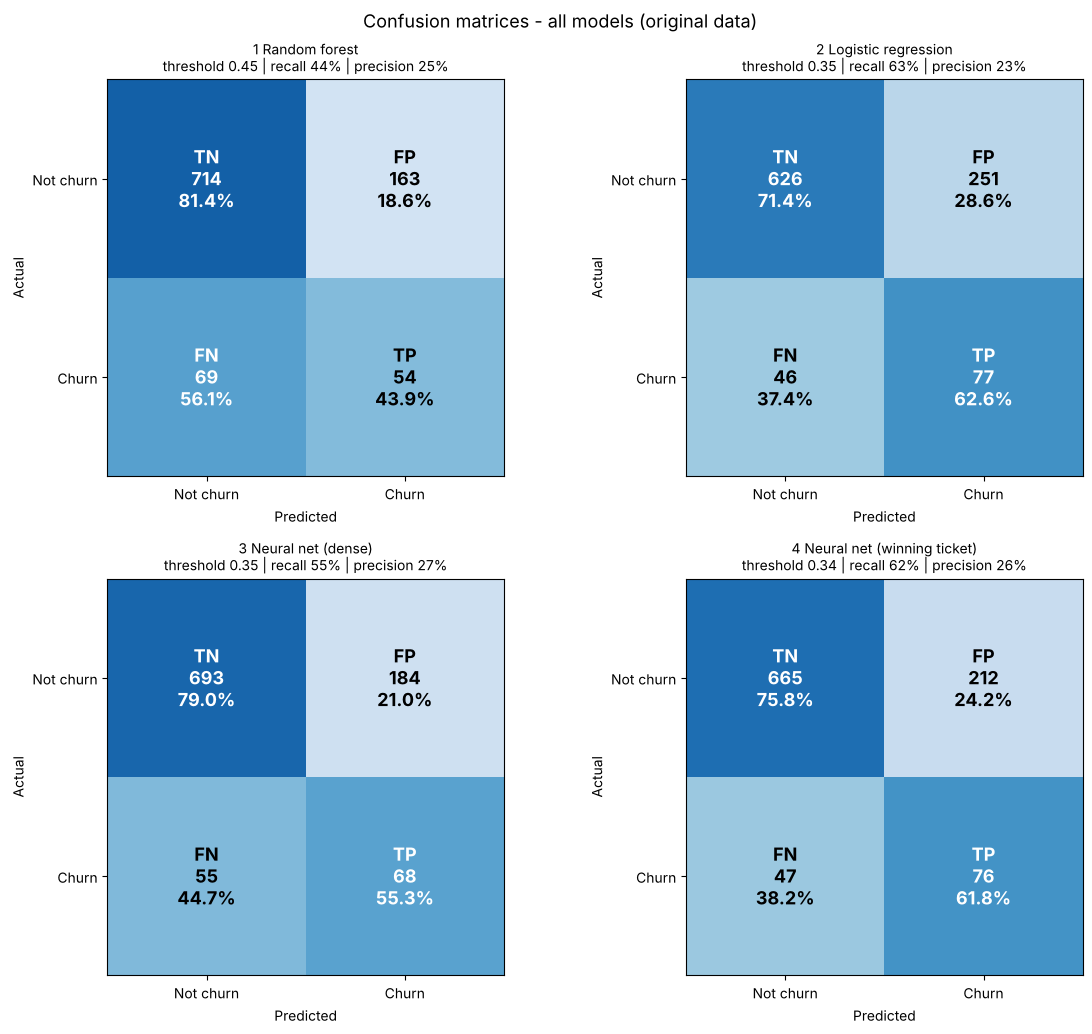

In [6]:
def draw_matrix(ax, tn, fp, fn, tp, title):
    cm = np.array([[tn, fp], [fn, tp]]); row_pct = cm / cm.sum(axis=1, keepdims=True); names = [["TN", "FP"], ["FN", "TP"]]
    ax.imshow(row_pct, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{names[i][j]}\n{cm[i, j]}\n{row_pct[i, j]:.1%}", ha="center", va="center",
                    color="white" if row_pct[i, j] > 0.5 else "black", fontsize=13, fontweight="bold")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Not churn", "Churn"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["Not churn", "Churn"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(title, fontsize=10)

fig, axes = plt.subplots(2, 2, figsize=(12, 10.5))
for ax, (name, r) in zip(axes.ravel(), table.iterrows()):
    draw_matrix(ax, int(r["TN"]), int(r["FP (false alarms)"]), int(r["FN (missed)"]), int(r["TP"]),
                f"{name}\nthreshold {r['Threshold']:.2f} | recall {r['Recall']:.0%} | precision {r['Precision']:.0%}")
fig.suptitle("Confusion matrices - all models (original data)", fontsize=13); fig.tight_layout(); plt.show()

## 6. ROC curves
The ROC curve shows how well each model ranks leavers above stayers across *all* thresholds.

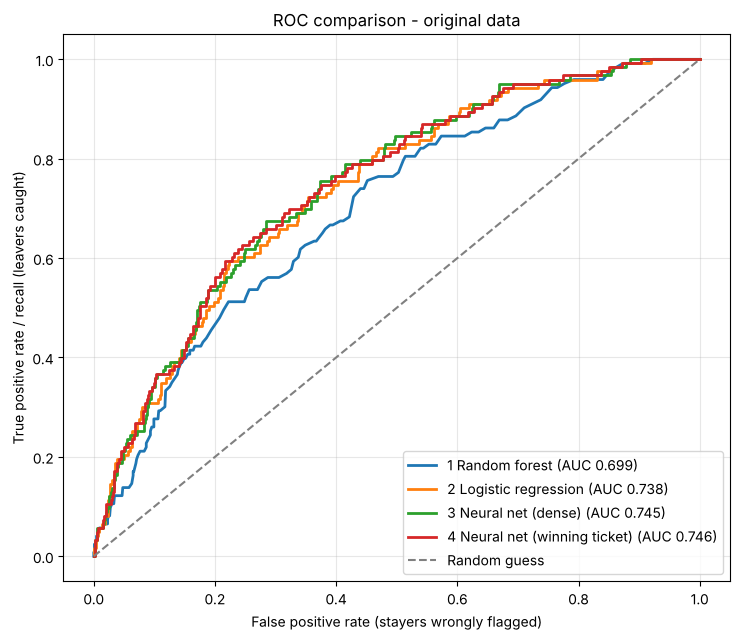

In [7]:
plt.figure(figsize=(7.5, 6.5))
for name, (p, thr) in results.items():
    f, t, _ = roc_curve(yv, p); plt.plot(f, t, linewidth=2, label=f"{name} (AUC {roc_auc_score(yv, p):.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Random guess")
plt.xlabel("False positive rate (stayers wrongly flagged)"); plt.ylabel("True positive rate / recall (leavers caught)")
plt.title("ROC comparison - original data"); plt.legend(loc="lower right"); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 7. Fair comparison: false alarms at the SAME recall
For each model, employees are ranked by score and false alarms are counted at the point where the required number of leavers has been caught. (The test set is used here only to compare the models like for like; it is not how thresholds are chosen above.)

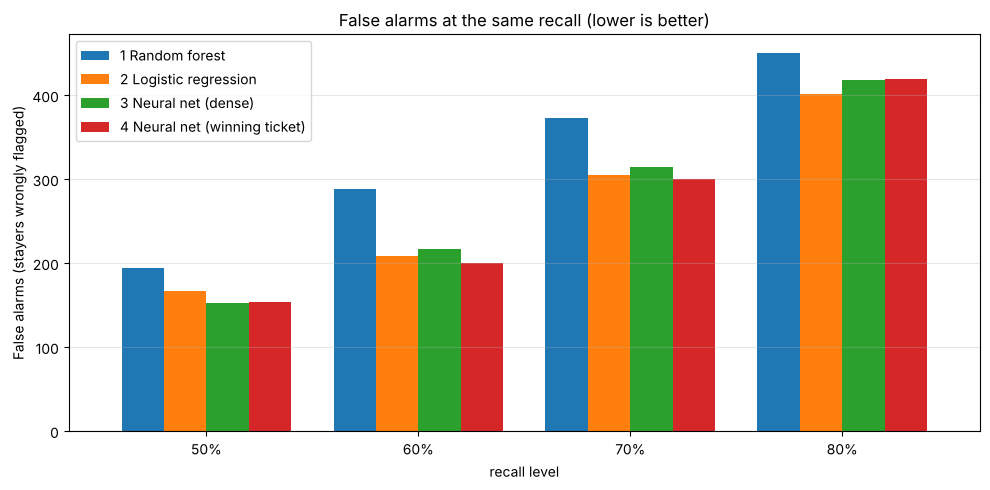

,leavers caught,1 Random forest,2 Logistic regression,3 Neural net (dense),4 Neural net (winning ticket)
recall level,,,,,
50%,62,194,167,153,154
60%,74,289,209,217,200
70%,87,373,305,315,300
80%,99,450,402,418,419


In [8]:
rows = []
for r in (0.5, 0.6, 0.7, 0.8):
    need = math.ceil(r * P); row = {"recall level": f"{r:.0%}", "leavers caught": need}
    for name, (p, _) in results.items():
        o = np.argsort(-p, kind="stable"); ys = yv[o]
        ctp, cfp = np.cumsum(ys), np.cumsum(1 - ys); row[name] = int(cfp[int(np.argmax(ctp >= need))])
    rows.append(row)
matched = pd.DataFrame(rows).set_index("recall level")
ax = matched.drop(columns="leavers caught").plot.bar(figsize=(10, 5), rot=0, width=0.8)
ax.set_ylabel("False alarms (stayers wrongly flagged)"); ax.set_title("False alarms at the same recall (lower is better)")
ax.grid(axis="y", alpha=0.3); plt.tight_layout(); plt.show()
matched

### Summary of the like-for-like comparison
How many fewer false alarms each model raises than the random forest at the same recall, and how the winning ticket compares with logistic regression.

In [9]:
models_only = [c for c in matched.columns if c != "leavers caught"]
vs_rf = pd.DataFrame({name: (matched["1 Random forest"] - matched[name]) / matched["1 Random forest"]
                      for name in models_only if name != "1 Random forest"})
vs_rf.loc["Average"] = vs_rf.mean()
ticket_vs_lr = matched["2 Logistic regression"] - matched["4 Neural net (winning ticket)"]     # positive = ticket has fewer false alarms

print(f"Versus the random forest at the same recall, average false alarms fall by "
      f"{vs_rf.loc['Average', '2 Logistic regression']:.0%} (logistic), "
      f"{vs_rf.loc['Average', '3 Neural net (dense)']:.0%} (neural net) and "
      f"{vs_rf.loc['Average', '4 Neural net (winning ticket)']:.0%} (winning ticket).")
print(f"Winning ticket vs logistic regression: {ticket_vs_lr.mean():+.1f} false alarms on average "
      f"(positive = ticket better); by recall level {ticket_vs_lr.tolist()}")
print(f"ROC AUC: logistic {table.loc['2 Logistic regression', 'ROC AUC']:.3f} vs winning ticket "
      f"{table.loc['4 Neural net (winning ticket)', 'ROC AUC']:.3f}  ->  within noise")
vs_rf.style.format("{:.1%}").set_caption("% fewer false alarms than the random forest (same recall)")

Versus the random forest at the same recall, average false alarms fall by 18% (logistic), 17% (neural net) and 19% (winning ticket).
Winning ticket vs logistic regression: +2.5 false alarms on average (positive = ticket better); by recall level [13, 9, 5, -17]
ROC AUC: logistic 0.738 vs winning ticket 0.746  ->  within noise


,2 Logistic regression,3 Neural net (dense),4 Neural net (winning ticket)
recall level,,,
50%,13.9%,21.1%,20.6%
60%,27.7%,24.9%,30.8%
70%,18.2%,15.5%,19.6%
80%,10.7%,7.1%,6.9%
Average,17.6%,17.2%,19.5%


## 8. Reading the result

- **Random forest (1)** is clearly the weakest: lowest AUC and the most false alarms at every recall level. Logistic regression and the neural networks each raise roughly 17-19% fewer false alarms than it on average (summary above).
- **Logistic regression (2) and the neural networks (3, 4) are essentially tied.** Their AUCs are within about 0.01 of each other, and false alarms at the same recall differ by only a handful either way - the neural network is slightly better at 50% recall and slightly worse at 80%. With one train/test split, differences this small are noise.
- **The winning ticket (4) matches the dense network (3)** with only about 6% of the weights, which is the weak form of the Lottery Ticket Hypothesis. Notebook 03 repeats this over 10 seeds and finds the rewound ticket barely beats a randomly re-initialised copy of the same sparse network.
- **The neural network does not beat logistic regression**, and it is harder to explain and tune, so the final model stays logistic regression.
- All models share the same ceiling (ROC AUC about 0.74-0.75): the limit is the information in the columns, not the algorithm.

**Caveats:** the network figures here come from a single random start (seed); notebook 03 shows the seed-to-seed spread is only about 0.002 AUC. All thresholds for models 2-4 were set from training data only; the matched-recall table in section 7 is for comparison only.